In [ ]:
# Google Colab dependencies
!pip install -q optuna catboost xgboost keras-tuner shap joblib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 18.0 MB/s eta 0:00:00


In [ ]:
import os
import random
import warnings
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone

from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import AdaBoostRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

import optuna

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("Libraries loaded successfully.")


Libraries loaded successfully.


In [ ]:
from pathlib import Path

def resolve_file(*names):
    candidates = []
    for name in names:
        candidates.extend([
            Path(name),
            Path("/content") / name,
            Path("/mnt/data") / name,
        ])
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(
        "Could not find any of: " + ", ".join(names) +
        ". Upload the three CSV files to Colab."
    )

TRAIN_FILE = resolve_file("train_data(1).csv", "train_data.csv")
TEST_FILE = resolve_file("test_data(1).csv", "test_data.csv")
FULL_FILE = resolve_file("preprocessed_full(1).csv", "preprocessed_full.csv")

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)
full_df = pd.read_csv(FULL_FILE)

print("Train file:", TRAIN_FILE)
print("Test file :", TEST_FILE)
print("Full file :", FULL_FILE)
print("\nTrain shape:", train_df.shape)
print("Test shape :", test_df.shape)
print("Full shape :", full_df.shape)


Train file: train_data.csv
Test file : test_data.csv
Full file : preprocessed_full.csv

Train shape: (780, 59)
Test shape : (196, 59)
Full shape : (976, 59)


In [ ]:
total = len(train_df) + len(test_df)

train_percentage = len(train_df) / total * 100
test_percentage = len(test_df) / total * 100

print(f"Processed dataset total : {total}")
print(f"Training                : {len(train_df)} ({train_percentage:.2f}%)")
print(f"Validation              : {len(test_df)} ({test_percentage:.2f}%)")

print("\nPaper context:")
print("- 1158 membranes were originally collected from OMD.")
print("- The modeling dataset is a processed/outlier-filtered dataset.")
print("- The paper then uses an 80/20 train-validation split.")

if total != 976:
    print("NOTE: the supplied processed files contain a different number of rows.")
if not (79 <= train_percentage <= 81):
    raise ValueError("The supplied train/test files are not approximately 80/20.")

assert len(full_df) == total, "preprocessed_full row count does not match train + test."


Processed dataset total : 976
Training                : 780 (79.92%)
Validation              : 196 (20.08%)

Paper context:
- 1158 membranes were originally collected from OMD.
- The modeling dataset is a processed/outlier-filtered dataset.
- The paper then uses an 80/20 train-validation split.


In [ ]:
TARGET = "A_over_B"

assert TARGET in train_df.columns
assert TARGET in test_df.columns

print("Target:", TARGET)

print("\nTraining target:")
print(train_df[TARGET].describe())

print("\nValidation target:")
print(test_df[TARGET].describe())

Target: A_over_B

Training target:
count    780.000000
mean       6.098178
std        5.724888
min        0.006969
25%        1.837400
50%        4.268333
75%        8.650617
max       25.200000
Name: A_over_B, dtype: float64

Validation target:
count    196.000000
mean       6.414509
std        6.085680
min        0.020214
25%        1.751084
50%        4.815000
75%        8.636070
max       25.221239
Name: A_over_B, dtype: float64


In [ ]:
print("Missing target values:")
print("Train:", train_df[TARGET].isna().sum())
print("Test :", test_df[TARGET].isna().sum())

Missing target values:
Train: 0
Test : 0


In [ ]:
for i, col in enumerate(train_df.columns):
    print(f"{i:02d} | {col}")

00 | Chem_Carbon nanotube
01 | Chem_Cellulose acetate
02 | Chem_Cellulose triacetate
03 | Chem_Graphene oxide
04 | Chem_Metal-organic framework
05 | Chem_Other
06 | Chem_Perfluorosulfonic acid-based polymer
07 | Chem_Polyacrylonitrile
08 | Chem_Polyamide
09 | Chem_Polyamine
10 | Chem_Polydopamine
11 | Chem_Polyester
12 | Chem_Polyethersulfone
13 | Chem_Polyethylene
14 | Chem_Polyethyleneimine
15 | Chem_Polyfurfurylalcohol
16 | Chem_Polyimide
17 | Chem_Polymers of intrinsic microporosity
18 | Chem_Polysulfone
19 | Chem_Polyvinylalcohol
20 | Chem_Zeolite
21 | S_Asymmetric
22 | S_Inorganic
23 | S_Other
24 | S_Polymeric TFC
25 | S_TFN / Hybrid
26 | M_No modification
27 | M_Other
28 | M_Post-treatment: solvent activation
29 | M_Post-treatment: solvent annealing
30 | M_Post-treatment: surface
31 | M_Synthesis: additives
32 | M_Synthesis: deposition method
33 | M_Synthesis: monomers
34 | M_Synthesis: solvent
35 | M_Synthesis: support
36 | Char_AFM
37 | Char_Ellipsometry
38 | Char_FTIR
39 | Ch

In [ ]:
chem_features = [c for c in train_df.columns if c.startswith("Chem_")]
structure_features = [c for c in train_df.columns if c.startswith("S_")]
modification_features = [c for c in train_df.columns if c.startswith("M_")]
characterization_features = [c for c in train_df.columns if c.startswith("Char_")]
filtration_features = [c for c in train_df.columns if c.startswith("FM_")]
cp_mode_features = [c for c in train_df.columns if c.startswith("CPMode_")]

print("Chemistry       :", len(chem_features))
print("Structure       :", len(structure_features))
print("Modification    :", len(modification_features))
print("Characterization:", len(characterization_features))
print("Filtration mode :", len(filtration_features))
print("CP mode         :", len(cp_mode_features))


Chemistry       : 21
Structure       : 5
Modification    : 10
Characterization: 9
Filtration mode : 3
CP mode         : 3


In [ ]:
LEAKAGE_OR_TARGET_DERIVED = [
    "A_over_B",
    "Robs",
    "Rreal"
]

In [ ]:
missing = (
    train_df
    .isna()
    .sum()
    .sort_values(ascending=False)
)

missing_percentage = (
    missing / len(train_df) * 100
)

missing_table = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": missing_percentage
})

missing_table[missing_table["Missing_Count"] > 0]

,Missing_Count,Missing_Percentage


In [ ]:
print("Missing values in training data:")
print(train_df.isna().sum().sum())

print("\nMissing values in validation data:")
print(test_df.isna().sum().sum())

Missing values in training data:
0

Missing values in validation data:
0


In [ ]:
assert list(train_df.columns) == list(test_df.columns)

print("Train/test columns match perfectly.")

Train/test columns match perfectly.


In [ ]:
assert TARGET not in train_df.drop(columns=[TARGET]).columns

print("Target is separated correctly.")

Target is separated correctly.


In [ ]:
# EXACT 43 INPUT FEATURES
#
# 21 chemistry + 5 structure + 10 modification
# + 3 filtration mode + 3 CP mode + 1 CP = 43.
#
# Characterization variables and other experimental variables are excluded.

EXPECTED_43_FEATURES = (
    chem_features
    + structure_features
    + modification_features
    + filtration_features
    + cp_mode_features
    + ["CP"]
)

assert len(chem_features) == 21
assert len(structure_features) == 5
assert len(modification_features) == 10
assert len(filtration_features) == 3
assert len(cp_mode_features) == 3
assert len(EXPECTED_43_FEATURES) == 43

missing_features = [
    c for c in EXPECTED_43_FEATURES
    if c not in train_df.columns
]
assert not missing_features, (
    "Required paper features missing from dataset: "
    + str(missing_features)
)

DESCRIPTOR_FEATURES = EXPECTED_43_FEATURES.copy()

assert "A_over_B" not in DESCRIPTOR_FEATURES
assert "Robs" not in DESCRIPTOR_FEATURES
assert "Rreal" not in DESCRIPTOR_FEATURES
assert "hydraulicP" not in DESCRIPTOR_FEATURES
assert "NaCl conc (M)" not in DESCRIPTOR_FEATURES
assert "osmoticP" not in DESCRIPTOR_FEATURES
assert "OtherSolutes" not in DESCRIPTOR_FEATURES

print("FINAL INPUT FEATURE COUNT:", len(DESCRIPTOR_FEATURES))
print("43-feature check PASSED.")


FINAL INPUT FEATURE COUNT: 43
43-feature check PASSED.


In [ ]:
X_train = train_df[DESCRIPTOR_FEATURES].copy()
y_train = train_df[TARGET].copy()

X_test = test_df[DESCRIPTOR_FEATURES].copy()
y_test = test_df[TARGET].copy()

# These CSVs are already the supplied processed modeling dataset.
# Do not remove additional outliers or columns here.

missing_train = int(X_train.isna().sum().sum())
missing_test = int(X_test.isna().sum().sum())

print("Missing values in 43 features:")
print("Train:", missing_train)
print("Test :", missing_test)

if missing_train or missing_test:
    raise ValueError(
        "The supplied processed CSVs contain missing values. "
        "Resolve the preprocessing before modeling instead of silently "
        "changing the reproduction dataset."
    )

non_numeric = X_train.select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric:
    raise TypeError("Non-numeric model inputs found: " + str(non_numeric))

DESCRIPTOR_FEATURES_FINAL = list(X_train.columns)

assert len(DESCRIPTOR_FEATURES_FINAL) == 43

print("\nX_train:", X_train.shape)
print("X_test :", X_test.shape)
print("Final model inputs: 43")


Missing values in 43 features:
Train: 0
Test : 0

X_train: (780, 43)
X_test : (196, 43)
Final model inputs: 43


In [ ]:
# Verify that preprocessed_full is exactly the union of train and validation files.
combined = pd.concat([train_df, test_df], ignore_index=True)

assert list(combined.columns) == list(full_df.columns)

full_hash = pd.util.hash_pandas_object(full_df, index=False).value_counts().sort_index()
combined_hash = pd.util.hash_pandas_object(combined, index=False).value_counts().sort_index()

assert full_hash.equals(combined_hash)

print("Dataset consistency check PASSED.")
print("preprocessed_full == train + test rows.")


Dataset consistency check PASSED.
preprocessed_full == train + test rows.


# Paper methodology lock

This notebook is locked to the supplied processed dataset and the paper's modeling structure:

- Target: **A/B water-salt selectivity**
- Model inputs: **43 features**
- Supplied processed dataset: **976 membranes**
- Split: **780 training / 196 validation = 80/20**
- Models: **MLP, kNN, SVR, AdaBoost, CatBoost, XGBoost, Random Forest**
- Hyperparameter optimization: **Bayesian optimization**
- Evaluation: **5-fold CV + MAE/RMSE/R²**
- Interpretation: **SHAP for CatBoost, XGBoost and Random Forest**

The paper originally collected 1158 membranes from OMD; the supplied 976-row files are treated as the already processed modeling dataset.


In [ ]:
CV = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print("5-fold cross-validation ready.")

5-fold cross-validation ready.


In [ ]:
def calculate_metrics(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    }

In [ ]:
def calculate_metrics(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    }


def evaluate_cv(model, X, y):
    r2_scores, mae_scores, rmse_scores = [], [], []

    for train_idx, val_idx in CV.split(X):
        fold_model = clone(model)

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]
        y_tr = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        fold_model.fit(X_tr, y_tr)
        pred = fold_model.predict(X_val)

        m = calculate_metrics(y_val, pred)
        r2_scores.append(m["R2"])
        mae_scores.append(m["MAE"])
        rmse_scores.append(m["RMSE"])

    return {
        "CV_R2_mean": float(np.mean(r2_scores)),
        "CV_R2_std": float(np.std(r2_scores)),
        "CV_MAE_mean": float(np.mean(mae_scores)),
        "CV_RMSE_mean": float(np.mean(rmse_scores))
    }


In [ ]:
rf_baseline = RandomForestRegressor(
    n_estimators=300,
    random_state=SEED,
    n_jobs=-1
)

rf_cv_results = evaluate_cv(
    rf_baseline,
    X_train,
    y_train
)

rf_cv_results

{'CV_R2_mean': 0.22137538973945575,
 'CV_R2_std': 0.06687221241392434,
 'CV_MAE_mean': 3.422168478856574,
 'CV_RMSE_mean': 5.028885320473492}

In [ ]:
MODEL_NAMES = [
    "MLP",
    "kNN",
    "SVR",
    "AdaBoost",
    "CatBoost",
    "XGBoost",
    "Random Forest"
]

print("Models to reproduce:")
for i, model in enumerate(MODEL_NAMES, 1):
    print(f"{i}. {model}")

Models to reproduce:
1. MLP
2. kNN
3. SVR
4. AdaBoost
5. CatBoost
6. XGBoost
7. Random Forest


In [ ]:
N_TRIALS = 30

sampler = optuna.samplers.TPESampler(
    seed=SEED
)

print(f"Bayesian optimization trials per model: {N_TRIALS}")

Bayesian optimization trials per model: 30


In [ ]:
def knn_objective(trial):

    n_neighbors = trial.suggest_int(
        "n_neighbors",
        2,
        30
    )

    weights = trial.suggest_categorical(
        "weights",
        ["uniform", "distance"]
    )

    p = trial.suggest_int(
        "p",
        1,
        2
    )

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(
            n_neighbors=n_neighbors,
            weights=weights,
            p=p
        ))
    ])

    scores = []

    for train_idx, val_idx in CV.split(X_train):

        model.fit(
            X_train.iloc[train_idx],
            y_train.iloc[train_idx]
        )

        pred = model.predict(
            X_train.iloc[val_idx]
        )

        scores.append(
            r2_score(
                y_train.iloc[val_idx],
                pred
            )
        )

    return np.mean(scores)

In [ ]:
knn_study = optuna.create_study(
    direction="maximize",
    sampler=sampler
)

knn_study.optimize(
    knn_objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

print("Best kNN parameters:")
print(knn_study.best_params)

print("Best CV R²:")
print(knn_study.best_value)

[I 2026-08-23 10:38:40,859] A new study created in memory with name: no-name-faaf08c3-838a-4925-b6ed-a6679372a112


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-23 10:38:41,122] Trial 0 finished with value: 0.23407419355721518 and parameters: {'n_neighbors': 12, 'weights': 'uniform', 'p': 2}. Best is trial 0 with value: 0.23407419355721518.
[I 2026-08-23 10:38:41,329] Trial 1 finished with value: 0.2434707040152065 and parameters: {'n_neighbors': 6, 'weights': 'uniform', 'p': 2}. Best is trial 1 with value: 0.2434707040152065.
[I 2026-08-23 10:38:41,596] Trial 2 finished with value: 0.20307381647058503 and parameters: {'n_neighbors': 19, 'weights': 'uniform', 'p': 2}. Best is trial 1 with value: 0.2434707040152065.
[I 2026-08-23 10:38:41,770] Trial 3 finished with value: 0.1853441411386642 and parameters: {'n_neighbors': 26, 'weights': 'uniform', 'p': 1}. Best is trial 1 with value: 0.2434707040152065.
[I 2026-08-23 10:38:41,890] Trial 4 finished with value: 0.2579726258765037 and parameters: {'n_neighbors': 10, 'weights': 'uniform', 'p': 1}. Best is trial 4 with value: 0.2579726258765037.
[I 2026-08-23 10:38:42,056] Trial 5 finishe

In [ ]:
best_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(
        **knn_study.best_params
    ))
])

best_knn.fit(X_train, y_train)

knn_train_pred = best_knn.predict(X_train)
knn_test_pred = best_knn.predict(X_test)

print("kNN")
print("Train R²:", r2_score(y_train, knn_train_pred))
print("Test R² :", r2_score(y_test, knn_test_pred))
print("Test MAE:", mean_absolute_error(y_test, knn_test_pred))
print("Test RMSE:", np.sqrt(
    mean_squared_error(y_test, knn_test_pred)
))

kNN
Train R²: 0.47418521009233183
Test R² : 0.2842405924589245
Test MAE: 3.4761248221034524
Test RMSE: 5.135490470480354


In [ ]:
def svr_objective(trial):

    C = trial.suggest_float(
        "C",
        1e-2,
        1e3,
        log=True
    )

    epsilon = trial.suggest_float(
        "epsilon",
        1e-3,
        0.5,
        log=True
    )

    gamma = trial.suggest_float(
        "gamma",
        1e-4,
        1e1,
        log=True
    )

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR(
            C=C,
            epsilon=epsilon,
            gamma=gamma
        ))
    ])

    scores = []

    for train_idx, val_idx in CV.split(X_train):

        model.fit(
            X_train.iloc[train_idx],
            y_train.iloc[train_idx]
        )

        pred = model.predict(
            X_train.iloc[val_idx]
        )

        scores.append(
            r2_score(
                y_train.iloc[val_idx],
                pred
            )
        )

    return np.mean(scores)

In [ ]:
svr_study = optuna.create_study(
    direction="maximize",
    sampler=sampler
)

svr_study.optimize(
    svr_objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

print("Best SVR parameters:")
print(svr_study.best_params)

print("Best CV R²:")
print(svr_study.best_value)

[I 2026-08-23 10:38:48,150] A new study created in memory with name: no-name-e0fb14ac-f47e-4fe2-b543-3aa0bba4e809


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-23 10:38:49,101] Trial 0 finished with value: -0.10796047227780518 and parameters: {'C': 0.0407559644007287, 'epsilon': 0.021700394405050148, 'gamma': 0.00014857392806279257}. Best is trial 0 with value: -0.10796047227780518.
[I 2026-08-23 10:38:50,420] Trial 1 finished with value: 0.13970129117625082 and parameters: {'C': 352.0481045526035, 'epsilon': 0.004993895014755658, 'gamma': 0.20540519425388448}. Best is trial 1 with value: 0.13970129117625082.
[I 2026-08-23 10:38:50,948] Trial 2 finished with value: 0.10410358338181913 and parameters: {'C': 0.36187233309596223, 'epsilon': 0.02533074654001447, 'gamma': 0.05414413211338523}. Best is trial 1 with value: 0.13970129117625082.
[I 2026-08-23 10:38:51,514] Trial 3 finished with value: -0.028569230151334835 and parameters: {'C': 0.08399864445957499, 'epsilon': 0.4138851334163266, 'gamma': 0.7510418138777541}. Best is trial 1 with value: 0.13970129117625082.
[I 2026-08-23 10:38:52,664] Trial 4 finished with value: 0.190619575

In [ ]:
best_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVR(
        **svr_study.best_params
    ))
])

best_svr.fit(X_train, y_train)

svr_train_pred = best_svr.predict(X_train)
svr_test_pred = best_svr.predict(X_test)

print("SVR")
print("Train R²:", r2_score(y_train, svr_train_pred))
print("Test R² :", r2_score(y_test, svr_test_pred))
print("Test MAE:", mean_absolute_error(y_test, svr_test_pred))
print("Test RMSE:", np.sqrt(
    mean_squared_error(y_test, svr_test_pred)
))

SVR
Train R²: 0.43279323742624354
Test R² : 0.2820926479506969
Test MAE: 3.3189927979378733
Test RMSE: 5.143190324092167


In [ ]:
def adaboost_objective(trial):

    n_estimators = trial.suggest_int(
        "n_estimators",
        50,
        500
    )

    learning_rate = trial.suggest_float(
        "learning_rate",
        0.001,
        1.0,
        log=True
    )

    max_depth = trial.suggest_int(
        "max_depth",
        1,
        6
    )

    model = AdaBoostRegressor(
        estimator=DecisionTreeRegressor(
            max_depth=max_depth,
            random_state=SEED
        ),
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        random_state=SEED
    )

    scores = []

    for train_idx, val_idx in CV.split(X_train):

        model.fit(
            X_train.iloc[train_idx],
            y_train.iloc[train_idx]
        )

        pred = model.predict(
            X_train.iloc[val_idx]
        )

        scores.append(
            r2_score(
                y_train.iloc[val_idx],
                pred
            )
        )

    return np.mean(scores)

In [ ]:
adaboost_study = optuna.create_study(
    direction="maximize",
    sampler=sampler
)

adaboost_study.optimize(
    adaboost_objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

print(adaboost_study.best_params)
print(adaboost_study.best_value)

[I 2026-08-23 10:39:10,098] A new study created in memory with name: no-name-21ee25d3-d81f-4c69-90d9-d92621d35f0f


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-23 10:39:15,084] Trial 0 finished with value: 0.08458725785437171 and parameters: {'n_estimators': 398, 'learning_rate': 0.0039459088110999985, 'max_depth': 1}. Best is trial 0 with value: 0.08458725785437171.
[I 2026-08-23 10:39:16,547] Trial 1 finished with value: 0.19743018115904726 and parameters: {'n_estimators': 417, 'learning_rate': 0.13199942261535016, 'max_depth': 5}. Best is trial 1 with value: 0.19743018115904726.
[I 2026-08-23 10:39:22,151] Trial 2 finished with value: 0.15419631585915367 and parameters: {'n_estimators': 397, 'learning_rate': 0.0016677615430197913, 'max_depth': 3}. Best is trial 1 with value: 0.19743018115904726.
[I 2026-08-23 10:39:22,556] Trial 3 finished with value: 0.1440928083489415 and parameters: {'n_estimators': 102, 'learning_rate': 0.3884277754703141, 'max_depth': 4}. Best is trial 1 with value: 0.19743018115904726.
[I 2026-08-23 10:39:25,044] Trial 4 finished with value: 0.11956185600255323 and parameters: {'n_estimators': 199, 'learni

In [ ]:
def catboost_objective(trial):

    iterations = trial.suggest_int(
        "iterations",
        100,
        1000
    )

    depth = trial.suggest_int(
        "depth",
        3,
        10
    )

    learning_rate = trial.suggest_float(
        "learning_rate",
        0.005,
        0.3,
        log=True
    )

    l2_leaf_reg = trial.suggest_float(
        "l2_leaf_reg",
        1e-2,
        100,
        log=True
    )

    model = CatBoostRegressor(
        iterations=iterations,
        depth=depth,
        learning_rate=learning_rate,
        l2_leaf_reg=l2_leaf_reg,
        loss_function="RMSE",
        verbose=False,
        random_seed=SEED
    )

    scores = []

    for train_idx, val_idx in CV.split(X_train):

        model.fit(
            X_train.iloc[train_idx],
            y_train.iloc[train_idx]
        )

        pred = model.predict(
            X_train.iloc[val_idx]
        )

        scores.append(
            r2_score(
                y_train.iloc[val_idx],
                pred
            )
        )

    return np.mean(scores)

In [ ]:
catboost_study = optuna.create_study(
    direction="maximize",
    sampler=sampler
)

catboost_study.optimize(
    catboost_objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

print("Best CatBoost:")
print(catboost_study.best_params)

print("CV R²:")
print(catboost_study.best_value)

[I 2026-08-23 10:40:29,905] A new study created in memory with name: no-name-d66a0a82-86b7-4da2-b598-04b78775b464


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-23 10:40:32,939] Trial 0 finished with value: 0.25724808465843096 and parameters: {'iterations': 128, 'depth': 8, 'learning_rate': 0.018111002276073877, 'l2_leaf_reg': 1.0821382910613992}. Best is trial 0 with value: 0.25724808465843096.
[I 2026-08-23 10:40:37,021] Trial 1 finished with value: 0.29522904153961405 and parameters: {'iterations': 917, 'depth': 4, 'learning_rate': 0.026834463202458136, 'l2_leaf_reg': 10.524574681335638}. Best is trial 1 with value: 0.29522904153961405.
[I 2026-08-23 10:40:37,838] Trial 2 finished with value: 0.22534430166172195 and parameters: {'iterations': 306, 'depth': 3, 'learning_rate': 0.016375399825825587, 'l2_leaf_reg': 0.044145368764944806}. Best is trial 1 with value: 0.29522904153961405.
[I 2026-08-23 10:41:09,047] Trial 3 finished with value: 0.33604548773961956 and parameters: {'iterations': 937, 'depth': 9, 'learning_rate': 0.06687405930123214, 'l2_leaf_reg': 30.608522106722507}. Best is trial 3 with value: 0.33604548773961956.
[I 

In [ ]:
def xgb_objective(trial):

    n_estimators = trial.suggest_int(
        "n_estimators",
        100,
        1000
    )

    max_depth = trial.suggest_int(
        "max_depth",
        2,
        10
    )

    learning_rate = trial.suggest_float(
        "learning_rate",
        0.005,
        0.3,
        log=True
    )

    subsample = trial.suggest_float(
        "subsample",
        0.5,
        1.0
    )

    colsample_bytree = trial.suggest_float(
        "colsample_bytree",
        0.5,
        1.0
    )

    min_child_weight = trial.suggest_int(
        "min_child_weight",
        1,
        10
    )

    reg_lambda = trial.suggest_float(
        "reg_lambda",
        1e-3,
        100,
        log=True
    )

    model = XGBRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        min_child_weight=min_child_weight,
        reg_lambda=reg_lambda,
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=-1
    )

    scores = []

    for train_idx, val_idx in CV.split(X_train):

        model.fit(
            X_train.iloc[train_idx],
            y_train.iloc[train_idx]
        )

        pred = model.predict(
            X_train.iloc[val_idx]
        )

        scores.append(
            r2_score(
                y_train.iloc[val_idx],
                pred
            )
        )

    return np.mean(scores)

In [ ]:
xgb_study = optuna.create_study(
    direction="maximize",
    sampler=sampler
)

xgb_study.optimize(
    xgb_objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

print("Best XGBoost:")
print(xgb_study.best_params)

print("CV R²:")
print(xgb_study.best_value)

[I 2026-08-23 10:47:04,132] A new study created in memory with name: no-name-7fbfe629-85e9-40d2-aca8-ccf394e4871c


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-23 10:47:06,463] Trial 0 finished with value: 0.28926122250734043 and parameters: {'n_estimators': 967, 'max_depth': 4, 'learning_rate': 0.03829596846392506, 'subsample': 0.6504391549083848, 'colsample_bytree': 0.6424202471887338, 'min_child_weight': 1, 'reg_lambda': 1.1164047352793702}. Best is trial 0 with value: 0.28926122250734043.
[I 2026-08-23 10:47:07,469] Trial 1 finished with value: 0.22338381970808205 and parameters: {'n_estimators': 552, 'max_depth': 2, 'learning_rate': 0.015647521722609477, 'subsample': 0.9541329429833268, 'colsample_bytree': 0.6197809453334862, 'min_child_weight': 2, 'reg_lambda': 0.28006820077310235}. Best is trial 0 with value: 0.28926122250734043.
[I 2026-08-23 10:47:09,624] Trial 2 finished with value: 0.23260071240358257 and parameters: {'n_estimators': 988, 'max_depth': 4, 'learning_rate': 0.07836617837752659, 'subsample': 0.8808098076643588, 'colsample_bytree': 0.6188187719961998, 'min_child_weight': 8, 'reg_lambda': 0.0690105777981331}. 

In [ ]:
def rf_objective(trial):

    n_estimators = trial.suggest_int(
        "n_estimators",
        100,
        1000
    )

    max_depth = trial.suggest_int(
        "max_depth",
        3,
        30
    )

    min_samples_split = trial.suggest_int(
        "min_samples_split",
        2,
        20
    )

    min_samples_leaf = trial.suggest_int(
        "min_samples_leaf",
        1,
        10
    )

    max_features = trial.suggest_categorical(
        "max_features",
        ["sqrt", "log2", 0.5, 1.0]
    )

    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        random_state=SEED,
        n_jobs=-1
    )

    scores = []

    for train_idx, val_idx in CV.split(X_train):

        model.fit(
            X_train.iloc[train_idx],
            y_train.iloc[train_idx]
        )

        pred = model.predict(
            X_train.iloc[val_idx]
        )

        scores.append(
            r2_score(
                y_train.iloc[val_idx],
                pred
            )
        )

    return np.mean(scores)

In [ ]:
rf_study = optuna.create_study(
    direction="maximize",
    sampler=sampler
)

rf_study.optimize(
    rf_objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

print("Best Random Forest:")
print(rf_study.best_params)

print("CV R²:")
print(rf_study.best_value)

[I 2026-08-23 10:48:40,229] A new study created in memory with name: no-name-fd4d42c1-118d-41fa-82a5-8e38364e7ba7


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-23 10:48:50,371] Trial 0 finished with value: 0.25011488679091254 and parameters: {'n_estimators': 594, 'max_depth': 22, 'min_samples_split': 14, 'min_samples_leaf': 3, 'max_features': 1.0}. Best is trial 0 with value: 0.25011488679091254.
[I 2026-08-23 10:48:58,071] Trial 1 finished with value: 0.19719956421989968 and parameters: {'n_estimators': 685, 'max_depth': 26, 'min_samples_split': 14, 'min_samples_leaf': 6, 'max_features': 'log2'}. Best is trial 0 with value: 0.25011488679091254.
[I 2026-08-23 10:49:09,258] Trial 2 finished with value: 0.2048504230114135 and parameters: {'n_estimators': 976, 'max_depth': 14, 'min_samples_split': 18, 'min_samples_leaf': 7, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.25011488679091254.
[I 2026-08-23 10:49:14,623] Trial 3 finished with value: 0.2661022623991718 and parameters: {'n_estimators': 275, 'max_depth': 23, 'min_samples_split': 7, 'min_samples_leaf': 1, 'max_features': 1.0}. Best is trial 3 with value: 0.266102262399

In [ ]:
import tensorflow as tf
import keras_tuner as kt

tf.random.set_seed(SEED)

print(tf.__version__)

2.20.0


In [ ]:
mlp_scaler = StandardScaler()

X_train_scaled = mlp_scaler.fit_transform(X_train)
X_test_scaled = mlp_scaler.transform(X_test)

print("MLP scaling complete.")

MLP scaling complete.


In [ ]:
def build_mlp(hp):
    model = tf.keras.Sequential()

    model.add(
        tf.keras.layers.Input(
            shape=(X_train_scaled.shape[1],)
        )
    )

    num_layers = hp.Int("num_layers", 1, 4, step=1)

    l2_value = hp.Float(
        "l2",
        min_value=1e-6,
        max_value=1e-2,
        sampling="log"
    )

    regularizer = tf.keras.regularizers.l2(l2_value)

    for i in range(num_layers):
        units = hp.Int(
            f"units_{i}",
            min_value=16,
            max_value=256,
            step=16
        )

        model.add(
            tf.keras.layers.Dense(
                units=units,
                activation="relu",
                kernel_regularizer=regularizer
            )
        )

        dropout = hp.Float(
            f"dropout_{i}",
            min_value=0.0,
            max_value=0.4,
            step=0.1
        )

        if dropout > 0:
            model.add(tf.keras.layers.Dropout(dropout))

    model.add(tf.keras.layers.Dense(1))

    learning_rate = hp.Float(
        "learning_rate",
        min_value=1e-4,
        max_value=1e-2,
        sampling="log"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model


In [ ]:
tuner = kt.BayesianOptimization(
    build_mlp,
    objective="val_loss",
    max_trials=30,
    directory="keras_tuner",
    project_name="RO_MLP",
    overwrite=True
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

tuner.search(
    X_train_scaled,
    y_train.values,
    validation_split=0.2,
    epochs=300,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Trial 30 Complete [00h 00m 26s]
val_loss: 18.90599250793457

Best val_loss So Far: 17.848508834838867
Total elapsed time: 00h 14m 10s


In [ ]:
best_mlp = tuner.get_best_models(
    num_models=1
)[0]

best_mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 176)            │         7,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 176)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 160)            │        28,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 160)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 112)            │        18,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         7,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,393 (239.82 KB)

 Trainable params: 61,393 (239.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
mlp_train_pred = best_mlp.predict(
    X_train_scaled,
    verbose=0
).ravel()

mlp_test_pred = best_mlp.predict(
    X_test_scaled,
    verbose=0
).ravel()

print("MLP")
print("Train R²:", r2_score(y_train, mlp_train_pred))
print("Test R² :", r2_score(y_test, mlp_test_pred))
print("Test MAE:", mean_absolute_error(y_test, mlp_test_pred))
print("Test RMSE:", np.sqrt(
    mean_squared_error(y_test, mlp_test_pred)
))

MLP
Train R²: 0.5180539693508102
Test R² : 0.368981773039737
Test MAE: 3.2315585864388865
Test RMSE: 4.8219127441537415


In [ ]:
best_mlp_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
BEST_MLP_HP = best_mlp_hp.values

def build_fixed_mlp(input_dim, hp):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(input_dim,)))

    regularizer = tf.keras.regularizers.l2(float(hp["l2"]))

    for i in range(int(hp["num_layers"])):
        model.add(
            tf.keras.layers.Dense(
                int(hp[f"units_{i}"]),
                activation="relu",
                kernel_regularizer=regularizer
            )
        )
        dropout = float(hp[f"dropout_{i}"])
        if dropout > 0:
            model.add(tf.keras.layers.Dropout(dropout))

    model.add(tf.keras.layers.Dense(1))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=float(hp["learning_rate"])
        ),
        loss="mse",
        metrics=["mae"]
    )
    return model


def evaluate_mlp_cv(X_scaled, y):
    r2s, maes, rmses = [], [], []

    for fold, (tr, va) in enumerate(CV.split(X_scaled), 1):
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED + fold)

        model = build_fixed_mlp(
            X_scaled.shape[1],
            BEST_MLP_HP
        )

        es = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=30,
            restore_best_weights=True
        )

        model.fit(
            X_scaled[tr],
            y.iloc[tr].values,
            validation_data=(X_scaled[va], y.iloc[va].values),
            epochs=300,
            batch_size=32,
            callbacks=[es],
            verbose=0
        )

        pred = model.predict(X_scaled[va], verbose=0).ravel()
        m = calculate_metrics(y.iloc[va], pred)

        r2s.append(m["R2"])
        maes.append(m["MAE"])
        rmses.append(m["RMSE"])

        print(
            f"MLP fold {fold}: "
            f"R²={m['R2']:.4f}, MAE={m['MAE']:.4f}, RMSE={m['RMSE']:.4f}"
        )

    return {
        "CV_R2_mean": float(np.mean(r2s)),
        "CV_R2_std": float(np.std(r2s)),
        "CV_MAE_mean": float(np.mean(maes)),
        "CV_RMSE_mean": float(np.mean(rmses))
    }


mlp_cv_results = evaluate_mlp_cv(X_train_scaled, y_train)
print("MLP 5-fold CV:", mlp_cv_results)


MLP fold 1: R²=0.2849, MAE=3.2539, RMSE=4.8759


MLP fold 2: R²=0.4035, MAE=2.9623, RMSE=3.9982


MLP fold 3: R²=0.3304, MAE=3.4609, RMSE=4.9504
MLP fold 4: R²=0.4236, MAE=3.0681, RMSE=4.2476
MLP fold 5: R²=0.5206, MAE=2.8965, RMSE=4.1037
MLP 5-fold CV: {'CV_R2_mean': 0.39257933582421806, 'CV_R2_std': 0.08117747176361968, 'CV_MAE_mean': 3.1283429376236715, 'CV_RMSE_mean': 4.4351624854808165}


In [ ]:
final_models = {}

final_models["kNN"] = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(
        **knn_study.best_params
    ))
])

final_models["SVR"] = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVR(
        **svr_study.best_params
    ))
])

final_models["AdaBoost"] = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=adaboost_study.best_params["max_depth"],
        random_state=SEED
    ),
    n_estimators=adaboost_study.best_params["n_estimators"],
    learning_rate=adaboost_study.best_params["learning_rate"],
    random_state=SEED
)

final_models["CatBoost"] = CatBoostRegressor(
    **catboost_study.best_params,
    loss_function="RMSE",
    verbose=False,
    random_seed=SEED
)

final_models["XGBoost"] = XGBRegressor(
    **xgb_study.best_params,
    objective="reg:squarederror",
    random_state=SEED,
    n_jobs=-1
)

final_models["Random Forest"] = RandomForestRegressor(
    **rf_study.best_params,
    random_state=SEED,
    n_jobs=-1
)

print("Final tree/kernel models created.")

Final tree/kernel models created.


In [ ]:
predictions = {}

results = []

# MLP
predictions["MLP_train"] = mlp_train_pred
predictions["MLP_test"] = mlp_test_pred

results.append({
    "Model": "MLP",
    "Train_R2": r2_score(y_train, mlp_train_pred),
    "Test_R2": r2_score(y_test, mlp_test_pred),
    "Test_MAE": mean_absolute_error(y_test, mlp_test_pred),
    "Test_RMSE": np.sqrt(
        mean_squared_error(y_test, mlp_test_pred)
    )
})


# Other six models
for name, model in final_models.items():

    print("Training:", name)

    model.fit(
        X_train,
        y_train
    )

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    predictions[f"{name}_train"] = train_pred
    predictions[f"{name}_test"] = test_pred

    metrics = {
        "Model": name,
        "Train_R2": r2_score(
            y_train,
            train_pred
        ),
        "Test_R2": r2_score(
            y_test,
            test_pred
        ),
        "Test_MAE": mean_absolute_error(
            y_test,
            test_pred
        ),
        "Test_RMSE": np.sqrt(
            mean_squared_error(
                y_test,
                test_pred
            )
        )
    }

    results.append(metrics)

results_df = pd.DataFrame(results)

results_df.sort_values(
    "Test_R2",
    ascending=False
)

Training: kNN
Training: SVR
Training: AdaBoost
Training: CatBoost
Training: XGBoost
Training: Random Forest


,Model,Train_R2,Test_R2,Test_MAE,Test_RMSE
6,Random Forest,0.624842,0.393944,3.322896,4.725577
4,CatBoost,0.585779,0.389391,3.341206,4.743293
5,XGBoost,0.604211,0.370821,3.434497,4.814880
0,MLP,0.518054,0.368982,3.231559,4.821913
1,kNN,0.474185,0.284241,3.476125,5.135490
2,SVR,0.432793,0.282093,3.318993,5.143190
3,AdaBoost,0.333695,0.275781,3.596662,5.165748


In [ ]:
cv_results = []

row = dict(mlp_cv_results)
row["Model"] = "MLP"
cv_results.append(row)

for name, model in final_models.items():
    row = evaluate_cv(model, X_train, y_train)
    row["Model"] = name
    cv_results.append(row)

cv_results_df = pd.DataFrame(cv_results)
cv_results_df


,CV_R2_mean,CV_R2_std,CV_MAE_mean,CV_RMSE_mean,Model
0,0.392579,0.081177,3.128343,4.435162,MLP
1,0.277099,0.076037,3.423240,4.842169,kNN
2,0.331228,0.096719,3.103195,4.656366,SVR
3,0.223567,0.065806,3.640247,5.016779,AdaBoost
4,0.357468,0.070091,3.261415,4.565022,CatBoost
5,0.339571,0.082231,3.328146,4.627075,XGBoost
6,0.330746,0.072637,3.281665,4.662112,Random Forest


In [ ]:
models_order = [
    "MLP", "kNN", "SVR", "AdaBoost",
    "CatBoost", "XGBoost", "Random Forest"
]

overall_rows = []

for name in models_order:
    y_all = np.concatenate([y_train.to_numpy(), y_test.to_numpy()])
    pred_all = np.concatenate([
        predictions[f"{name}_train"],
        predictions[f"{name}_test"]
    ])

    overall_rows.append({
        "Model": name,
        "Overall_R2": r2_score(y_all, pred_all)
    })

overall_df = pd.DataFrame(overall_rows)

final_results = (
    results_df
    .merge(cv_results_df, on="Model", how="left")
    .merge(overall_df, on="Model", how="left")
)

final_results = final_results[
    [
        "Model",
        "Train_R2",
        "Test_R2",
        "Overall_R2",
        "Test_MAE",
        "Test_RMSE",
        "CV_R2_mean",
        "CV_R2_std",
        "CV_MAE_mean",
        "CV_RMSE_mean"
    ]
]

final_results.sort_values("Test_R2", ascending=False)


,Model,Train_R2,Test_R2,Overall_R2,Test_MAE,Test_RMSE,CV_R2_mean,CV_R2_std,CV_MAE_mean,CV_RMSE_mean
6,Random Forest,0.624842,0.393944,0.574134,3.322896,4.725577,0.330746,0.072637,3.281665,4.662112
4,CatBoost,0.585779,0.389391,0.542695,3.341206,4.743293,0.357468,0.070091,3.261415,4.565022
5,XGBoost,0.604211,0.370821,0.552964,3.434497,4.814880,0.339571,0.082231,3.328146,4.627075
0,MLP,0.518054,0.368982,0.485430,3.231559,4.821913,0.392579,0.081177,3.128343,4.435162
1,kNN,0.474185,0.284241,0.432575,3.476125,5.135490,0.277099,0.076037,3.423240,4.842169
2,SVR,0.432793,0.282093,0.399852,3.318993,5.143190,0.331228,0.096719,3.103195,4.656366
3,AdaBoost,0.333695,0.275781,0.321250,3.596662,5.165748,0.223567,0.065806,3.640247,5.016779


## Comparison with reported paper results

Reported overall R² values:
MLP 0.7072, kNN 0.7708, CatBoost 0.7746, XGBoost 0.7706, Random Forest 0.7225.

Reported validation R² values from the paper's prediction figure:
MLP 0.6698, kNN 0.6469, CatBoost 0.6986, XGBoost 0.6956, Random Forest 0.6492.


In [ ]:
paper_reference = pd.DataFrame({
    "Model": ["MLP", "kNN", "CatBoost", "XGBoost", "Random Forest"],
    "Paper_Overall_R2": [0.7072, 0.7708, 0.7746, 0.7706, 0.7225]
})

comparison = final_results.merge(
    paper_reference,
    on="Model",
    how="left"
)

comparison["Overall_R2_Difference"] = (
    comparison["Overall_R2"] - comparison["Paper_Overall_R2"]
)

display(comparison)

comparison.to_csv(
    "reproduction_results/paper_comparison.csv",
    index=False
)


,Model,Train_R2,Test_R2,Overall_R2,Test_MAE,Test_RMSE,CV_R2_mean,CV_R2_std,CV_MAE_mean,CV_RMSE_mean,Paper_Overall_R2,Overall_R2_Difference
0,MLP,0.518054,0.368982,0.485430,3.231559,4.821913,0.392579,0.081177,3.128343,4.435162,0.7072,-0.221770
1,kNN,0.474185,0.284241,0.432575,3.476125,5.135490,0.277099,0.076037,3.423240,4.842169,0.7708,-0.338225
2,SVR,0.432793,0.282093,0.399852,3.318993,5.143190,0.331228,0.096719,3.103195,4.656366,NaN,NaN
3,AdaBoost,0.333695,0.275781,0.321250,3.596662,5.165748,0.223567,0.065806,3.640247,5.016779,NaN,NaN
4,CatBoost,0.585779,0.389391,0.542695,3.341206,4.743293,0.357468,0.070091,3.261415,4.565022,0.7746,-0.231905
5,XGBoost,0.604211,0.370821,0.552964,3.434497,4.814880,0.339571,0.082231,3.328146,4.627075,0.7706,-0.217636
6,Random Forest,0.624842,0.393944,0.574134,3.322896,4.725577,0.330746,0.072637,3.281665,4.662112,0.7225,-0.148366


In [ ]:
os.makedirs(
    "reproduction_results",
    exist_ok=True
)

final_results.to_csv(
    "reproduction_results/model_comparison.csv",
    index=False
)

print("Results saved.")

Results saved.


In [ ]:
plot_df = final_results.copy()

models_order = [
    "MLP",
    "kNN",
    "SVR",
    "AdaBoost",
    "CatBoost",
    "XGBoost",
    "Random Forest"
]

plot_df["Model"] = pd.Categorical(
    plot_df["Model"],
    categories=models_order,
    ordered=True
)

plot_df = plot_df.sort_values("Model")

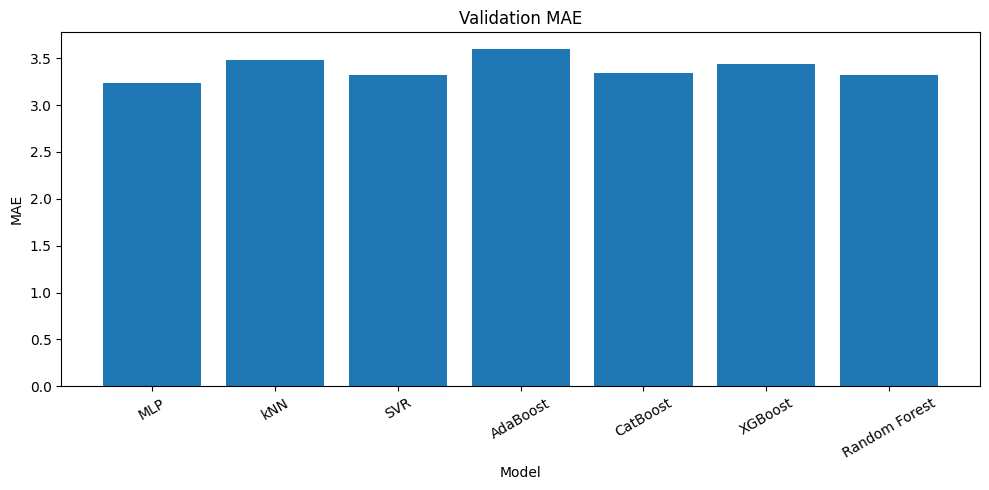

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    plot_df["Model"],
    plot_df["Test_MAE"]
)

plt.ylabel("MAE")
plt.xlabel("Model")
plt.title("Validation MAE")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

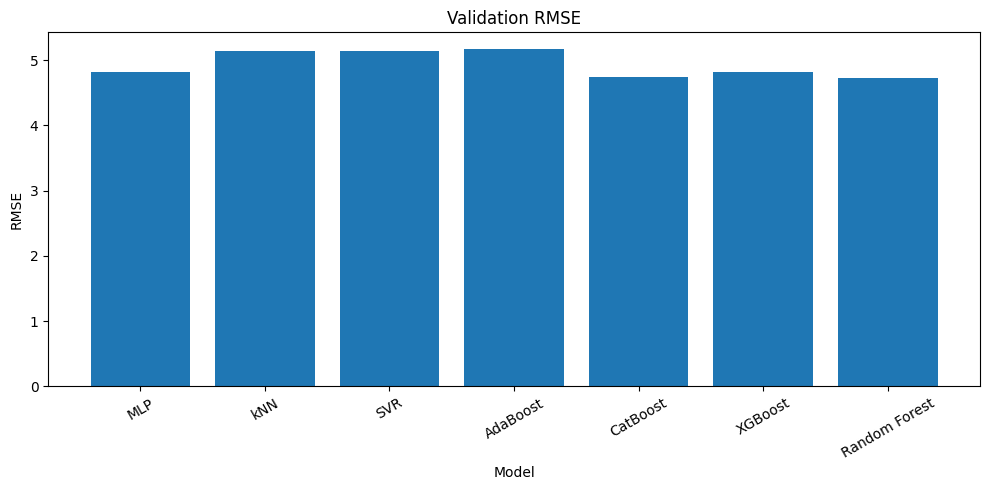

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    plot_df["Model"],
    plot_df["Test_RMSE"]
)

plt.ylabel("RMSE")
plt.xlabel("Model")
plt.title("Validation RMSE")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

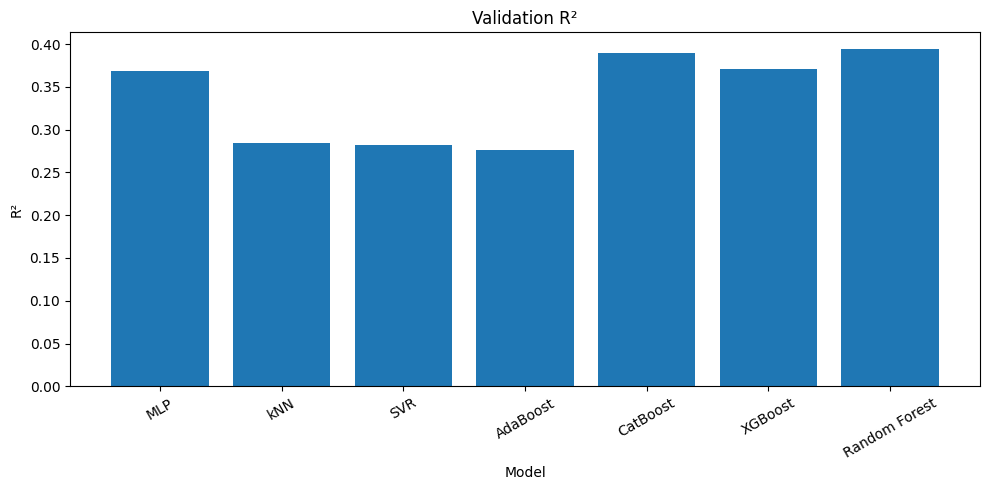

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    plot_df["Model"],
    plot_df["Test_R2"]
)

plt.ylabel("R²")
plt.xlabel("Model")
plt.title("Validation R²")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
def prediction_plot(
    model_name,
    y_train,
    train_pred,
    y_test,
    test_pred
):

    plt.figure(figsize=(7, 6))

    plt.scatter(
        y_train,
        train_pred,
        alpha=0.6,
        label="Training Data"
    )

    plt.scatter(
        y_test,
        test_pred,
        alpha=0.6,
        label="Validation Data"
    )

    minimum = min(
        y_train.min(),
        y_test.min()
    )

    maximum = max(
        y_train.max(),
        y_test.max()
    )

    plt.plot(
        [minimum, maximum],
        [minimum, maximum],
        linestyle="--",
        label="R² = 1"
    )

    plt.xlabel("Target")
    plt.ylabel("Prediction")

    train_r2 = r2_score(
        y_train,
        train_pred
    )

    test_r2 = r2_score(
        y_test,
        test_pred
    )

    plt.title(
        f"{model_name}\n"
        f"Training R² = {train_r2:.4f} | "
        f"Validation R² = {test_r2:.4f}"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()

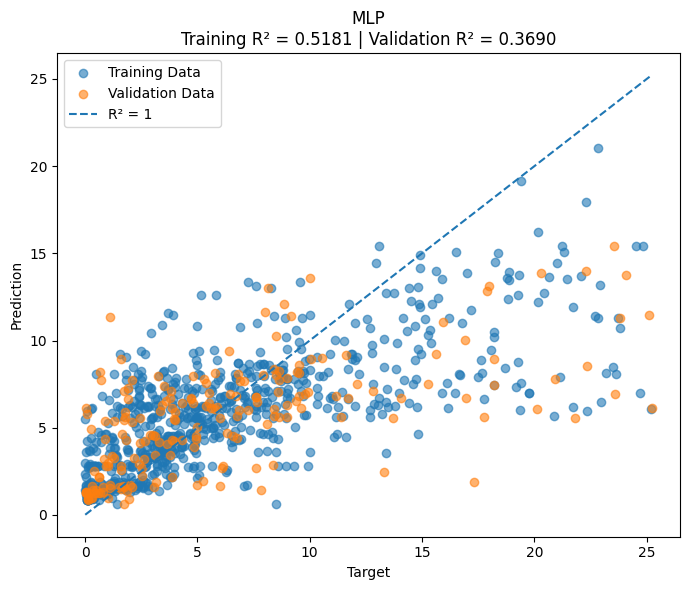

In [ ]:
prediction_plot(
    "MLP",
    y_train,
    predictions["MLP_train"],
    y_test,
    predictions["MLP_test"]
)

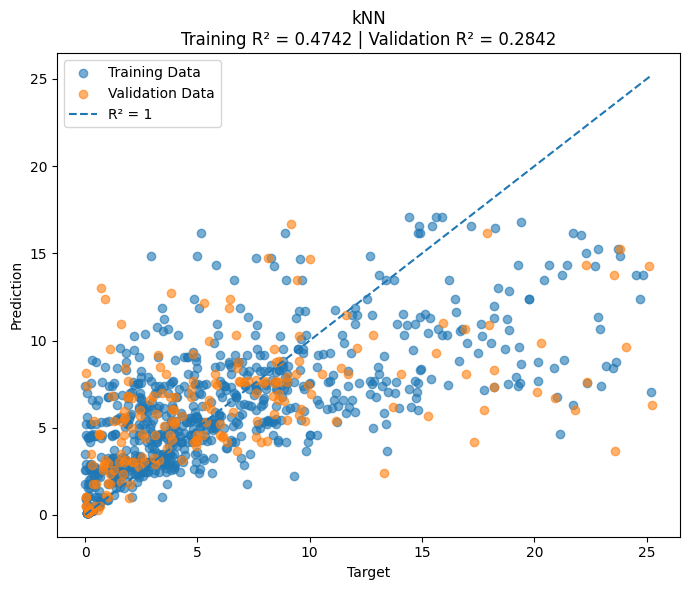

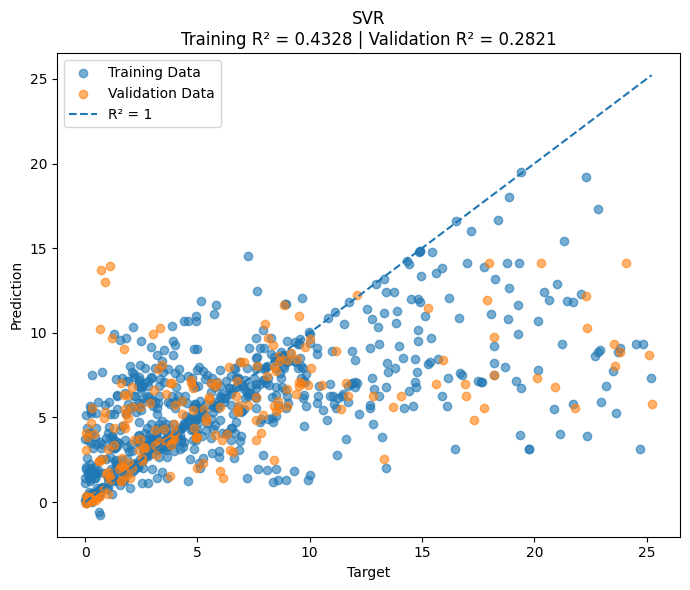

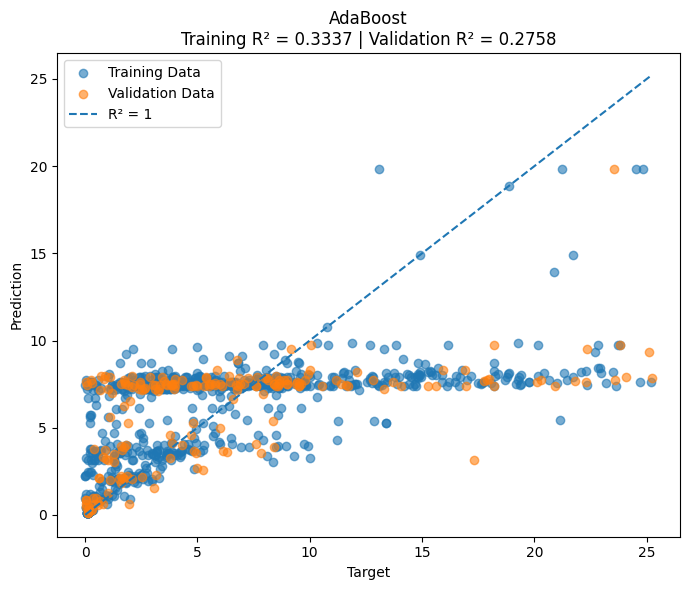

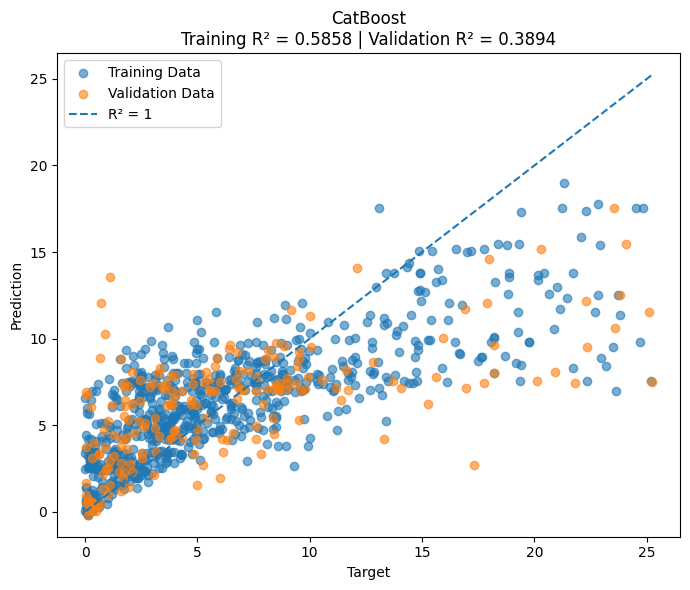

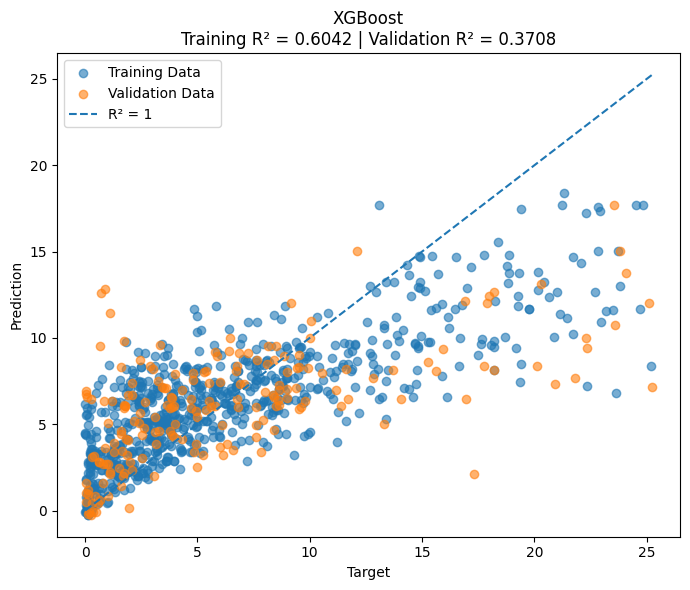

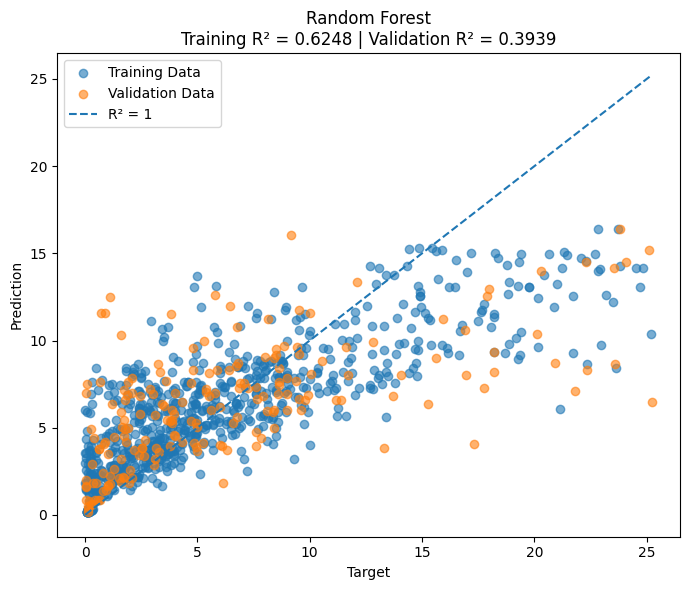

In [ ]:
for name in final_models.keys():

    prediction_plot(
        name,
        y_train,
        predictions[f"{name}_train"],
        y_test,
        predictions[f"{name}_test"]
    )

## SHAP analysis

The paper's Figure 3 reports SHAP values from **CatBoost, XGBoost and Random Forest** for individual membrane features.

The paper also states that key feature importance was cross-checked across **CatBoost, XGBoost, Random Forest and MLP**. The notebook therefore:
1. Runs SHAP for the three tree models used in Figure 3.
2. Keeps MLP in the overall performance comparison.
3. Saves top-15 SHAP rankings for each tree model.


In [ ]:
import shap

os.makedirs("reproduction_results/shap", exist_ok=True)

SHAP_MODELS = ["CatBoost", "XGBoost", "Random Forest"]
shap_values_by_model = {}
shap_importance_tables = {}

for name in SHAP_MODELS:
    model = final_models[name]

    explainer = shap.TreeExplainer(model)
    values = explainer.shap_values(X_test)

    if isinstance(values, list):
        values = values[0]

    values = np.asarray(values)
    shap_values_by_model[name] = values

    importance = pd.DataFrame({
        "Feature": X_test.columns,
        "Mean_Abs_SHAP": np.mean(np.abs(values), axis=0)
    }).sort_values("Mean_Abs_SHAP", ascending=False)

    shap_importance_tables[name] = importance

    importance.to_csv(
        f"reproduction_results/shap/{name.lower().replace(' ', '_')}_shap_importance.csv",
        index=False
    )

    print(f"\n{name} - top 15 features")
    display(importance.head(15))

print("SHAP analysis complete.")



CatBoost - top 15 features


,Feature,Mean_Abs_SHAP
42,CP,0.796562
8,Chem_Polyamide,0.745949
34,M_Synthesis: solvent,0.539095
31,M_Synthesis: additives,0.463570
37,FM_Dead-end,0.449204
26,M_No modification,0.335196
33,M_Synthesis: monomers,0.242083
39,CPMode_As reported,0.189541
24,S_Polymeric TFC,0.175873
32,M_Synthesis: deposition method,0.171642



XGBoost - top 15 features


,Feature,Mean_Abs_SHAP
42,CP,1.020223
8,Chem_Polyamide,0.845909
34,M_Synthesis: solvent,0.645447
31,M_Synthesis: additives,0.588017
37,FM_Dead-end,0.508815
26,M_No modification,0.457842
5,Chem_Other,0.282655
24,S_Polymeric TFC,0.265325
38,FM_Not available,0.232069
39,CPMode_As reported,0.227145



Random Forest - top 15 features


,Feature,Mean_Abs_SHAP
42,CP,0.711483
8,Chem_Polyamide,0.633862
37,FM_Dead-end,0.471449
34,M_Synthesis: solvent,0.407343
31,M_Synthesis: additives,0.367486
26,M_No modification,0.306369
19,Chem_Polyvinylalcohol,0.247741
36,FM_Cross-flow,0.197566
33,M_Synthesis: monomers,0.173160
41,CPMode_Not available,0.165257


SHAP analysis complete.



CatBoost SHAP summary


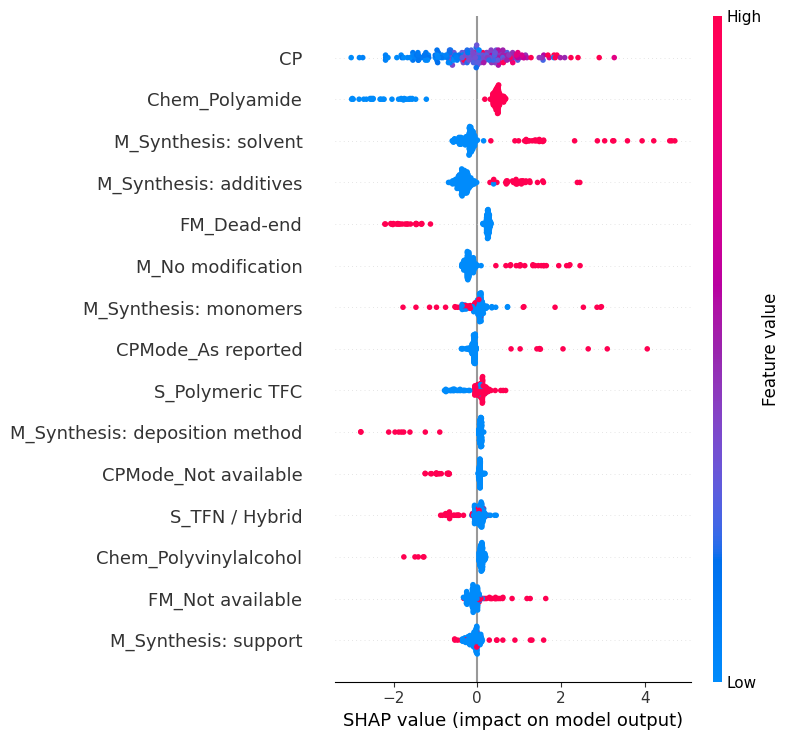

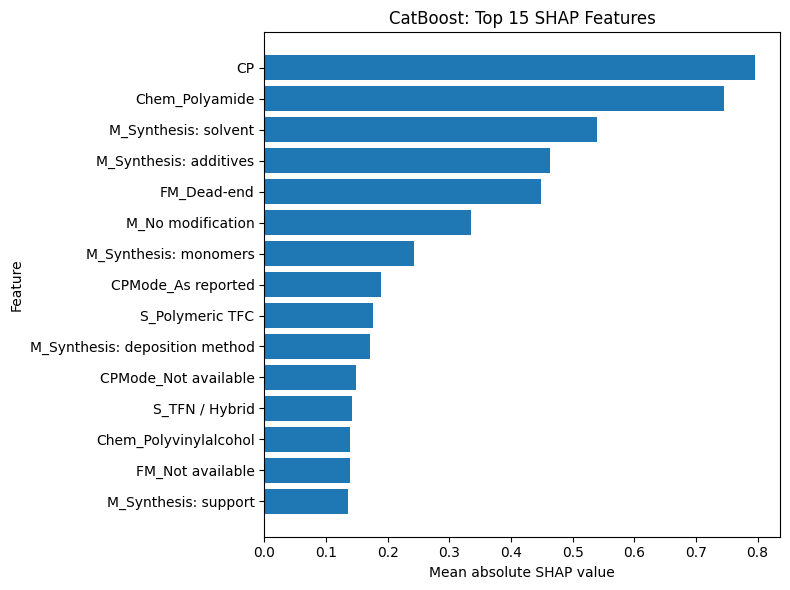


XGBoost SHAP summary


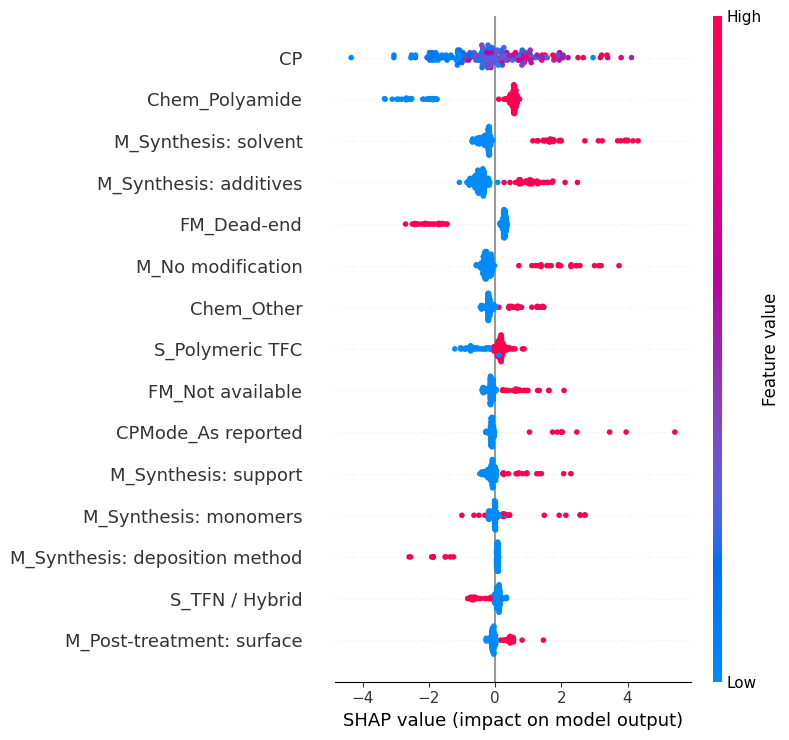

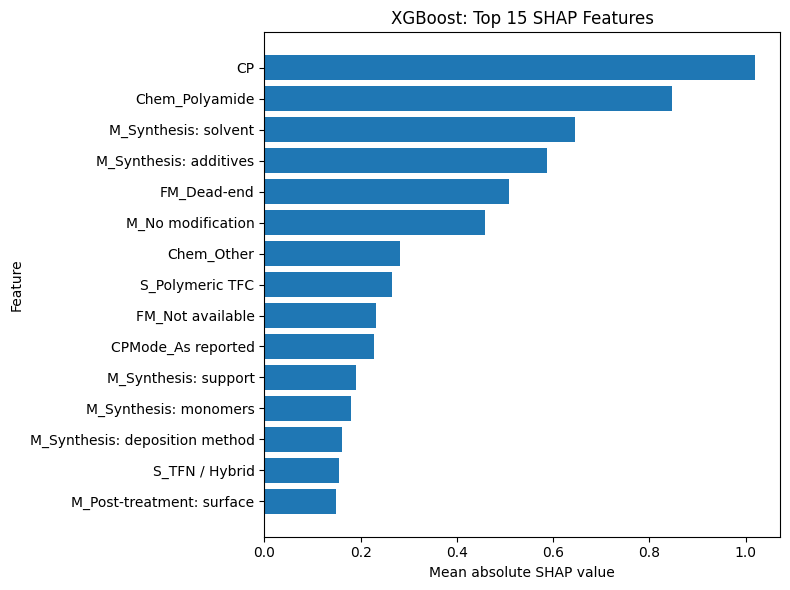


Random Forest SHAP summary


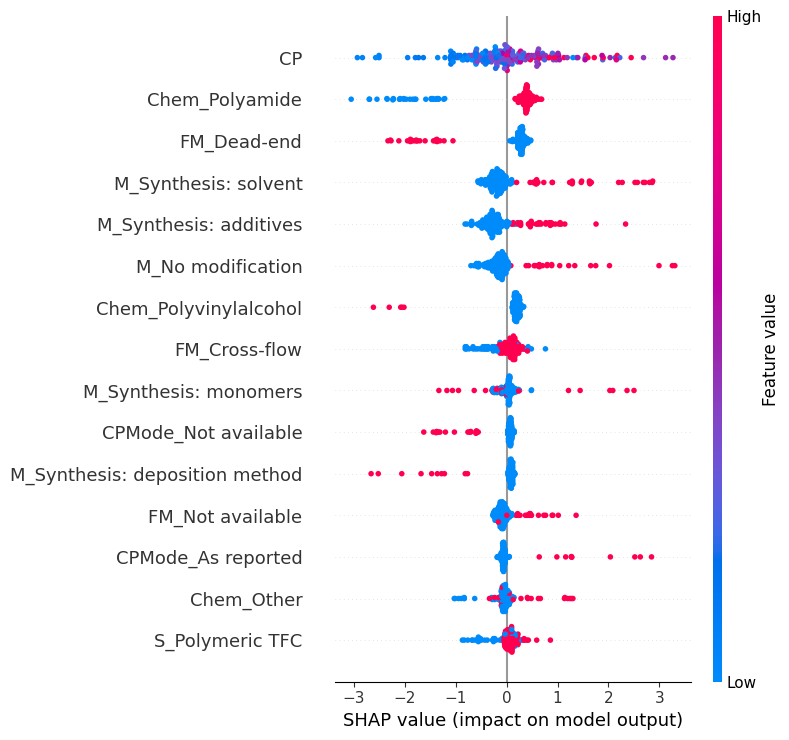

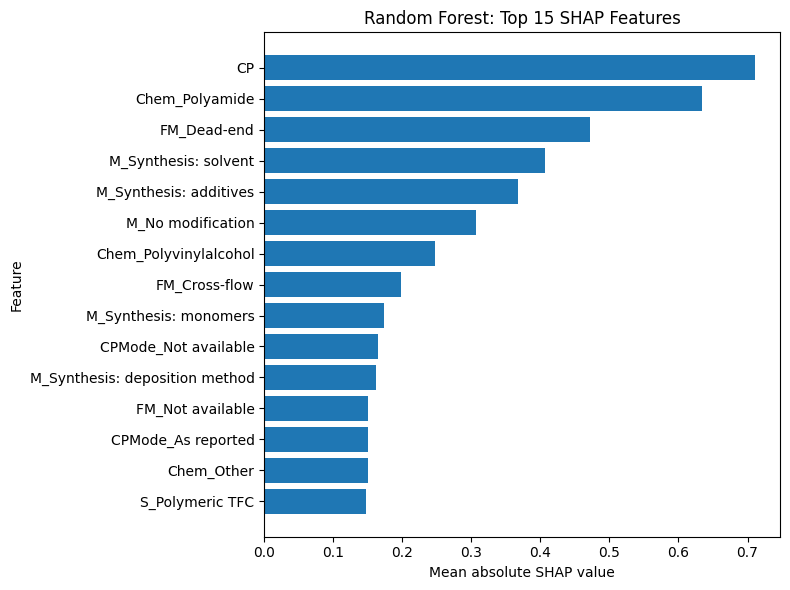

In [ ]:
for name in SHAP_MODELS:
    print(f"\n{name} SHAP summary")
    shap.summary_plot(
        shap_values_by_model[name],
        X_test,
        max_display=15,
        show=True
    )

    top15 = shap_importance_tables[name].head(15).sort_values(
        "Mean_Abs_SHAP",
        ascending=True
    )

    plt.figure(figsize=(8, 6))
    plt.barh(top15["Feature"], top15["Mean_Abs_SHAP"])
    plt.xlabel("Mean absolute SHAP value")
    plt.ylabel("Feature")
    plt.title(f"{name}: Top 15 SHAP Features")
    plt.tight_layout()
    plt.savefig(
        f"reproduction_results/shap/{name.lower().replace(' ', '_')}_top15_bar.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


In [ ]:
os.makedirs(
    "reproduction_results/models",
    exist_ok=True
)

for name, model in final_models.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + ".joblib"
    )

    joblib.dump(
        model,
        f"reproduction_results/models/{filename}"
    )

print("Six sklearn/tree models saved.")

Six sklearn/tree models saved.


In [ ]:
best_mlp.save(
    "reproduction_results/models/mlp.keras"
)

joblib.dump(
    mlp_scaler,
    "reproduction_results/models/mlp_scaler.joblib"
)

print("MLP saved.")

MLP saved.


In [ ]:
best_parameters = {
    "MLP": BEST_MLP_HP,
    "kNN": knn_study.best_params,
    "SVR": svr_study.best_params,
    "AdaBoost": adaboost_study.best_params,
    "CatBoost": catboost_study.best_params,
    "XGBoost": xgb_study.best_params,
    "Random Forest": rf_study.best_params
}

with open(
    "reproduction_results/best_hyperparameters.json",
    "w"
) as f:
    json.dump(
        best_parameters,
        f,
        indent=4,
        default=lambda x: x.item() if hasattr(x, "item") else x
    )

print("All seven model hyperparameters saved.")


All seven model hyperparameters saved.


In [ ]:
reproduction_metadata = {
    "paper": "Materials 2025, 18, 840",
    "target": TARGET,
    "processed_samples": int(total),
    "train_samples": int(len(train_df)),
    "validation_samples": int(len(test_df)),
    "final_input_features": int(len(DESCRIPTOR_FEATURES_FINAL)),
    "cv_folds": 5,
    "bayesian_trials_per_model": N_TRIALS,
    "shap_models": SHAP_MODELS,
    "paper_original_omd_samples": 1158,
    "paper_reported_input_features": 43,
    "paper_reported_overall_r2": {
        "MLP": 0.7072,
        "kNN": 0.7708,
        "CatBoost": 0.7746,
        "XGBoost": 0.7706,
        "Random Forest": 0.7225
    }
}

with open(
    "reproduction_results/reproduction_metadata.json",
    "w"
) as f:
    json.dump(reproduction_metadata, f, indent=4)

print(json.dumps(reproduction_metadata, indent=2))


{
  "paper": "Materials 2025, 18, 840",
  "target": "A_over_B",
  "processed_samples": 976,
  "train_samples": 780,
  "validation_samples": 196,
  "final_input_features": 43,
  "cv_folds": 5,
  "bayesian_trials_per_model": 30,
  "shap_models": [
    "CatBoost",
    "XGBoost",
    "Random Forest"
  ],
  "paper_original_omd_samples": 1158,
  "paper_reported_input_features": 43,
  "paper_reported_overall_r2": {
    "MLP": 0.7072,
    "kNN": 0.7708,
    "CatBoost": 0.7746,
    "XGBoost": 0.7706,
    "Random Forest": 0.7225
  }
}
